# TP2 : Estimation de densité par noyaux

## G3 SDI - Introduction à l'Estimation Statistique

Dans le cadre de cours, nous avons étudié jusqu'à présent des méthodes d'estimation dites paramétriques : on se fixe une famille de lois paramétrique à laquelle la loi ayant généré les données est censée appartenir, puis on cherche à estimer les paramètres à partir des données (par exemple par maximum de vraisemblance).

Dans ce TP, nous introduisons une méthode d'estimation **non-paramétrique** de la fonction de densité appelée estimation par noyaux (*kernel estimation* en anglais). C'est-à-dire que nous ne faisons plus d'hypothèse sur la loi ayant généré les données, et nous cherchons plutôt à estimer directement la densité de la loi parente $f$ (que l'on supposera continue). Ainsi cette méthode ne concerne que les variables aléatoires continues.

### Instructions

1. Renommez votre notebook sous la forme `tp2_Nom1_Nom2.ipynb`. 

2. Votre code et les résultats obtenus doivent être commentés !

3. Déposez votre notebook sur Moodle dans la section prévue à cet effet avant la date limite.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Compte-rendu écrit par FERNANDES--STRAG Henry, TORRES--Leguet Alexandre, 13/10/26.
</div>

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import scipy.stats as ss
import seaborn as sns

### Partie 1 - Histogrammes

On considère $(x_1, ..., x_n)$ $n$ réalisations indépendantes d'une variable aléatoire réelle.

Soit $x_0 \in \mathbb{R}$ et $h > 0$. On partitionne la droite réelle en intervalles de même longueur $h$, aussi appelés *bins* :
$$\forall k \in \mathbb{Z},~B_k =~]x_0 + (k-1)h~;~x_0 + kh].$$

L'histogramme est une fonction constante par morceaux définie de la manière suivante :
$$\forall x \in B_k,~H_n(x) = n_k,$$
où $n_k$ est le nombre de réalisations appartenant à l'intervalle $B_k$.

**Q1**. Comment normaliser $H_n$ pour obtenir un estimateur de la fonction de densité ? On rappelera que $\int_{\mathbb{R}} f(x) dx = 1$.

Dans la suite, on note $\hat{f}_n$ cet estimateur de $f$.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Par construction, $\int_{\mathbb{R}} H_n(x)\,dx = \sum_k n_k\,h = nh$. Pour obtenir une densité, on divise par $nh$ :
$$\hat{f}_n(x) = \frac{H_n(x)}{nh} = \frac{n_k}{nh} \quad \text{pour } x \in B_k.$$
Ici $n_k/n$ est la fréquence empirique de $B_k$, qui estime $p_k = \int_{B_k} f \approx h\,f(x)$.

</div>

**Q2 (bonus).** Pour tout $x \in \mathbb{R}$, calculer le biais et la variance de $\hat{f}_n(x)$. Commenter.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Soit $x \in B_k = \,]a_k, a_k+h]$ et $p_k = \int_{B_k} f$. Alors $n_k \sim \mathrm{Bin}(n, p_k)$, donc on peut tout calculer : 

- **Espérance** : $\mathbb{E}[\hat f_n(x)] = p_k/h$.
- **Biais** : $\dfrac{p_k}{h} - f(x) = \dfrac1h\displaystyle\int_{B_k}\big(f(t)-f(x)\big)dt \approx f'(x)\,\big(a_k + \tfrac h2 - x\big)$ (Taylor à l'ordre 1), donc $|\text{biais}| \lesssim \tfrac h2 |f'(x)| = O(h)$.
- **Variance** : $\dfrac{p_k(1-p_k)}{nh^2} \approx \dfrac{f(x)}{nh}$, car $p_k \approx h f(x)$.

Lorsque $h$ diminue, le biais diminue mais la variance augmente (et inversement) : c'est le compromis biais-variance. L'estimateur est convergent si $h \to 0$ et $nh \to \infty$.

</div>

**Q3**. On fixe $x_0 = \min_i x_i$. La valeur de $h$ peut être fixée indirectement en fixant à la place le nombre de *bins* $N_b$ entre $\min_i x_i$ et $\max_i x_i$, on a alors
$$h = \frac{\max_i x_i - \min_i x_i}{N_b}.$$

Générer 200 points d'un modèle de mélange gaussien 1D à 2 composantes avec $\mu_1 = -2.5, \mu_2 = 1.5, \sigma_1 = \sigma_2 = 1, \pi_1 = 0.4, \pi_2 = 0.6$.

Montrer l'influence de la valeur de $h$ sur l'histogramme normalisé (prendre les valeurs de Nb suggérées dans la cellule de code).

On utilisera la fonction `np.histogram` pour calculer automatiquement les $n_k$, et la fonction `plt.bar` pour représenter $\hat{f}_n$. Superposer la densité théorique du modèle de mélange gaussien. Commenter.

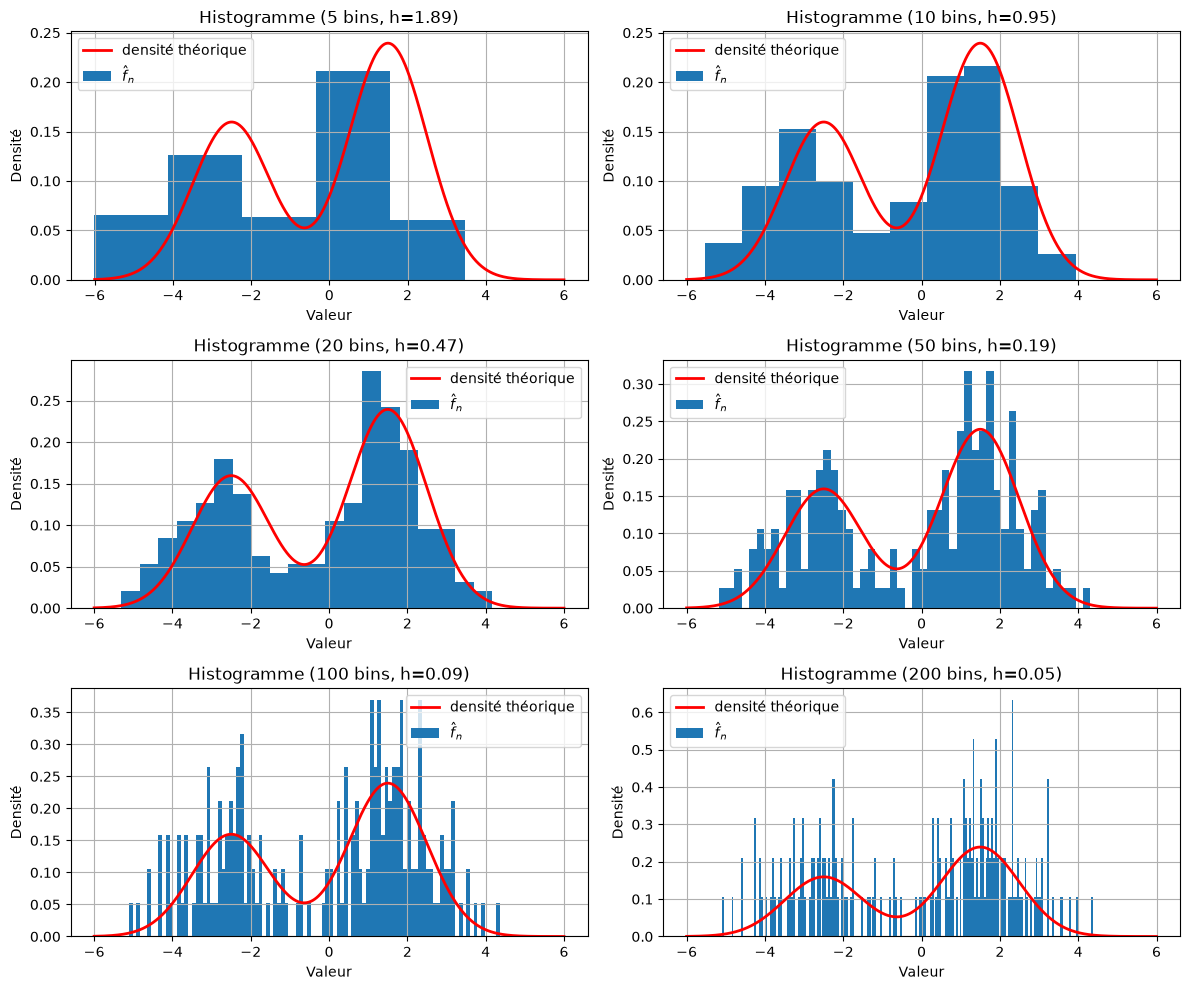

In [2]:
# Generate data from GMM

rng = np.random.default_rng(seed=42)

N = 200
Nb_list = [5, 10, 20, 50, 100, 200]

mu = np.array([-2.5, 1.5])
sigma = np.array([1.0, 1.0])
pi = np.array([0.4, 0.6])

Z = rng.choice(2, size=N, p=pi) # on tire toutes les variables latentes Z en même temps (0 ou 1)
X = rng.normal(mu[Z], sigma[Z])

# Plot histograms with varying number of bins

x = np.linspace(-6, 6, 1000)
f_true = sum(p * ss.norm.pdf(x, m, s) for p, m, s in zip(pi, mu, sigma)) # densité théorique de probabilité de la GMM sur la grille

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for i, Nb in enumerate(Nb_list):
    ax = axes[i // 2, i % 2]

    nk, bin_edges = np.histogram(X, bins=Nb) # nk=valeurs sur les B_k, bin_edges=le début des B_k
    h = bin_edges[1] - bin_edges[0] # largeur des bins (=max - min / Nb)
    f_hat = nk / (N * h) # normalisation de la Q1
    assert np.isclose(np.sum(f_hat * h), 1) # vérification : l'histogramme intègre bien à 1

    ax.bar(bin_edges[:-1], f_hat, width=h, label=r'$\hat f_n$')

    # plot de la densité théorique
    ax.plot(x, f_true, 'r-', lw=2, label='densité théorique')

    ax.set_title(f'Histogramme ({Nb} bins, h={h:.2f})')
    ax.set_xlabel('Valeur')
    ax.set_ylabel('Densité')
    ax.grid()
    ax.legend()

plt.tight_layout()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On observe que lorsque $h$ est grand, l'estimation de $f$ est peu précise et ne révèle pas sa forme. Les bins sont si larges que le creux entre les deux modes du mélange est écrasé et que la position des modes est imprécise. **On remarque donc visuellement qu'un grand $h$ implique un estimateur avec un haut biais, car en moyenne l'estimation sera toujous éloignée de $f$. Elle possède cependant une faible variance puisqu'elle dépend de $n_k$ (le nombre d'échantillons qui tombent dans $B_k$) où $B_k$ est relativement grand : ce nombre ne change pas beaucoup entre plusieurs tirages de données.**

A contrario, une estimation avec une valeur de $h$ trop petite n'a plus de sens car elle est trop "diluée". L'histogramme devient bruité, avec de nombreux bins quasiment vides et des pics isolés. **Le biais est donc faible, car en moyenne l'estimation se rapproche de $f$. Cependant, on a une variance élevée car les $n_k$ dépendent des intervalles $B_k$ qui sont beaucoup plus petits : d'un tirage à l'autre, le nombre de réalisations qui tombent dans $B_k$ varie donc beaucoup.**

Ces conclusions sont les mêmes de celles trouvée à partir des formules théoriques du biais et de la variance pour $\hat{f}_n$.

Une valeur intermédiaire semble donc optimale, ici autour de $N_b$ entre 20 et 30 visuellement.

</div>

**Q4**. Quelles sont les principales limitations de l'utilisation de l'histogramme comme estimateur de la fonction de densité ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Les limitations principales de cette méthode sont :
- la forte dépendance à la longueur des bins $h$, ainsi qu'au choix de $x_0$.
- l'estimation obtenue est constante par morceaux, qui est éloignée des types de fonction de densité usuels (dérivables, continues...)
- la longueur des bins est uniforme, on pourrait imaginer que certains domaines requièrent une précision plus haute que d'autres pour approximer $f$.

</div>

### Partie 2 - Estimation par noyaux en 1D

$(x_1, ..., x_n)$ sont toujours $n$ réalisations indépendantes d'une variable aléatoire réelle.

L'une des motivations principales est de faire directement dépendre l'estimation des données, et de ne plus dépendre de découpages arbitraires de $\mathbb{R}$. Pour cela, on propose la méthodologie suivante :
- Choisir une fonction $K$ appelée "noyau". On choisit $K$ positive ou nulle, symétrique, et d'intégrale 1.
- Centrer $K$ sur chaque observation $x_i$.
- L'estimateur à noyaux est alors
$$\hat{f}_n(x) = \frac{1}{n} \sum_{i=1}^n K(x - x_i).$$

On pourra par exemple choisir des noyaux $K$ continus, dérivables partout... Propriétés dont $\hat{f}_n$ héritera.

**Q1**. On utilise dans un premier temps un noyau gaussien :
$$K(x) = \frac{1}{\sqrt{2 \pi}} \exp \left( -\frac{x^2}{2} \right).$$

Prendre 10 observations des données générées dans la partie 1. Sur un même graphique, représenter les 10 noyaux (normalisés par $n$) centrés sur les observations, et l'estimateur à noyaux $\hat{f}_n$. Superposer la vraie densité $f$. Commenter.

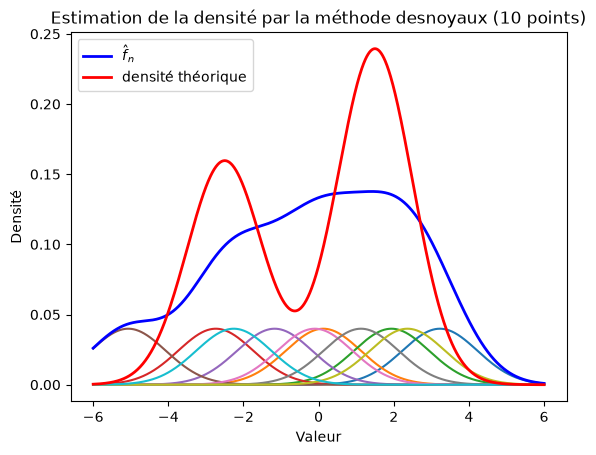

In [ ]:
# Randomly select 10 points from previously generated dataset

rng = np.random.default_rng(seed=423)

X_subset = rng.choice(X, size=10, replace=False)

# Implement the kernel density estimator and plot it

def K(x):
    return (1 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * x**2)

x = np.linspace(-6, 6, 1000)

# ici on fait une boucle sur les observations pour pouvoir afficher tous les noyaux
for i in range(len(X_subset)):
    K_i = K(x - X_subset[i]) # noyau centré sur X_subset[i]
    plt.plot(x, K_i/len(X_subset))

# calcul vectorisé
# on doit soustraire à chaque x (N,) chacune des observations de X_subset (10,)
# on passe donc par une matrice de taille (N, 10) ((N,1) - (10) via du broadcasting), puis on moyenne sur l'axe 1
f_hat = K(x[:, None] - X_subset).mean(axis=1)

plt.plot(x, f_hat, 'b-', lw=2, label=r'$\hat f_n$')
plt.plot(x, f_true, 'r-', lw=2, label='densité théorique')
plt.title('Estimation de la densité par la méthode des noyaux (10 points)')
plt.xlabel('Valeur')
plt.ylabel('Densité')
plt.legend()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Chaque observation apporte une « bosse » de masse $1/n$. Avec seulement $n = 10$ points, il est cependant peu fiable. Ici, un point peu probable tiré à -5 apporte une masse considérable autour de -5 à $\hat{f}_n$ : le 2e mode est donc sous-estimé et mal centré. Le résultat dépend fortement des quelques points tirés.

On remarque aussi que l'estimation obtenue est très différente de celle obtenue par la méthode de l'histogramme : la fonction est continue et dérivable et "ressemble" à une vrai densité de probabilité.


</div>

**Q2**. En réalité, on va faire dépendre cet estimateur d'un paramètre de lissage $h > 0$, qu'on appelle largeur de fenêtre (ou *bandwidth* en anglais).

Le (véritable) estimateur à noyaux, aussi appelé méthode de Parzen-Rosenblatt (du nom des deux statisticiens l'ayant développée) est :
$$\hat{f}_n(x) = \frac{1}{nh} \sum_{i=1}^n K(\frac{x - x_i}{h}).$$

(On peut facilement vérifier que $\hat{f}_n(x)$ intègre bien à 1).

Implémenter cet estimateur sur les données générées dans la partie 1, et montrer l'influence de la valeur de $h$. Commenter.

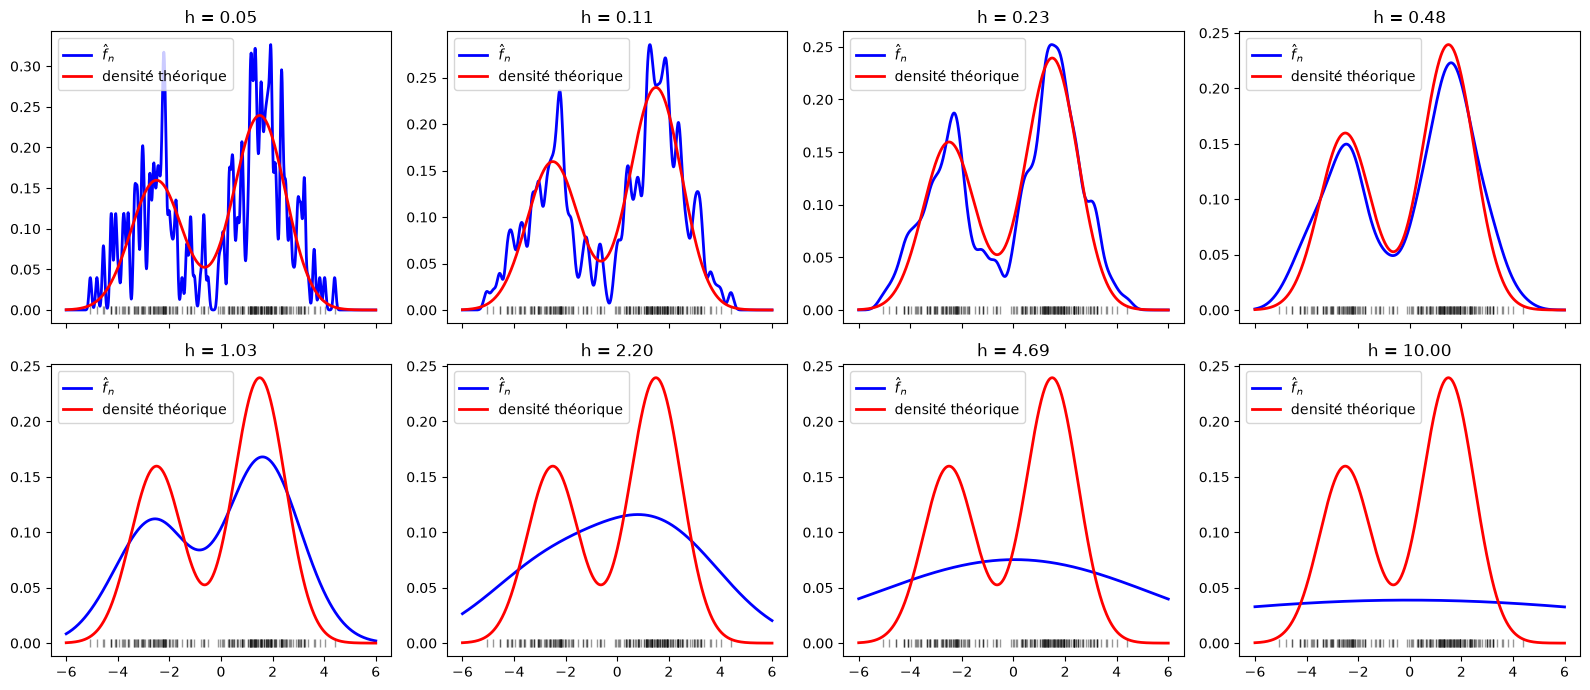

In [4]:
H = np.logspace(np.log10(0.05), np.log10(10.0), 8)
#H = np.linspace(0.05, 10.0, 8)
 
x = np.linspace(-6, 6, 1000)
 
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
for ax, h in zip(axes.ravel(), H):
    f_hat = K((x[:, None] - X) / h).mean(axis=1) / h # même calcul que précédemment, avec les 2 divisions par h en plus
    ax.plot(X, np.zeros(len(X)), 'k|', alpha=0.4) # on affiche en y=0 les observations
    ax.plot(x, f_hat, 'b-', lw=2, label=r'$\hat f_n$')
    ax.plot(x, f_true, 'r-', lw=2, label='densité théorique')
    
    ax.set_title(f'h = {h:.2f}')
    ax.legend()
 
plt.tight_layout()
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

- **$h$ très petit** ($\leq 0.05$) : un pic étroit sur chaque observation (le cas limite $h \to 0$ est une somme de Diracs). La variance est énorme et l'estimateur est très irrégulier.
- **$h$ intermédiaire** ($\approx 0.3$ à $0.5$) : estimation proche de la vraie densité, avec les deux modes bien retrouvés.
- **$h$ grand** : à $h = 1$ la bimodalité est encore visible mais trop aplatie, et à partir de $h = 2$ les deux modes fusionnent. Le biais domine.

On rapproche ces résultats des analyses faites à la question Q3, puisque la méthode des noyaux généralise la méthode des histogrammes à n'importe quelle fonction continue (ici K le noyau gaussien), là où la méthode des histogramme utilisait K qui est la fonction échelon. Les conclusions sur l'impact de $h$ et le compromis qu'il faut trouver sont donc les mêmes.

</div>

**Q3.** Nous allons maintenant regarder d'autres noyaux. Cette fois-ci, nous n'implémenterons pas l'estimateur à la main mais ferons appel à la librairie `scikit-learn` qui implémente six noyaux différents (dont le noyau gaussien). La méthode est implémentée dans `sklearn.neighbors.KernelDensity` (voir la doc [ici](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KernelDensity.html)).

Représenter les six noyaux. Commenter.

À longueur de fenêtre fixée (par exemple $h = 0.5$), montrer l'influence des différentes fenêtres. Commenter.

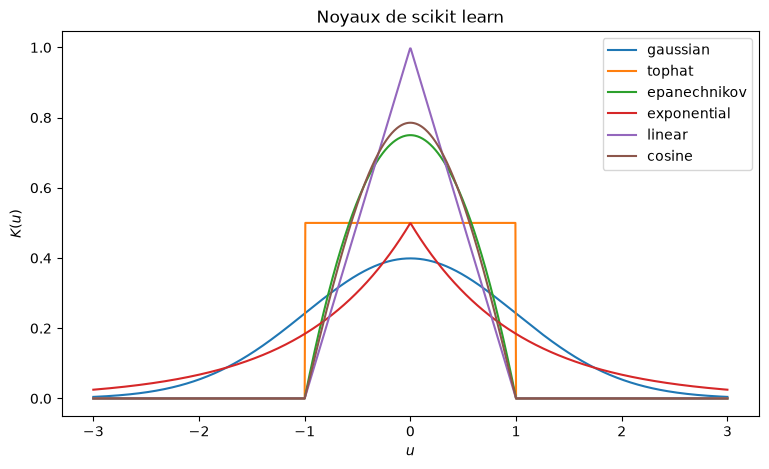

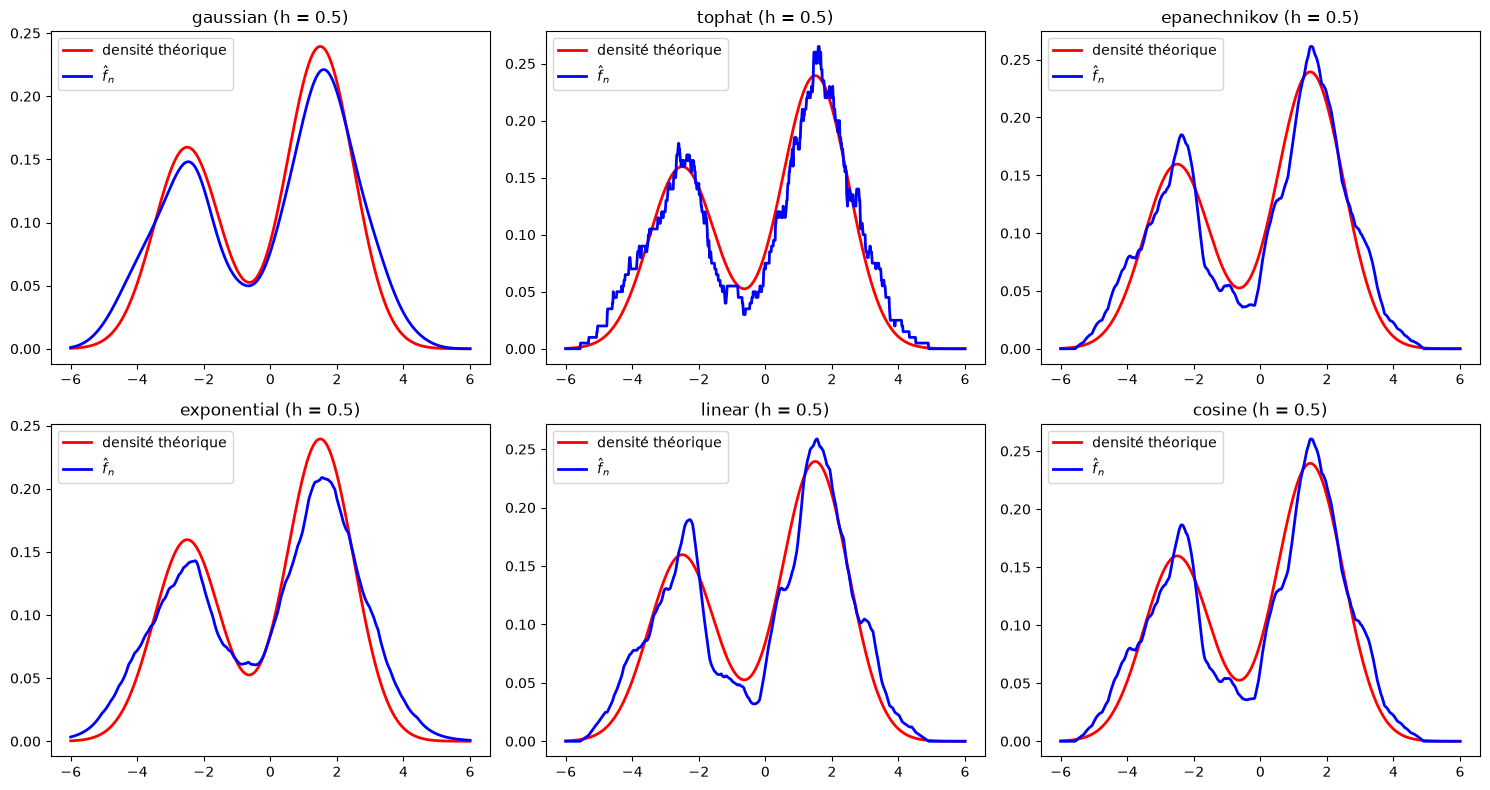

In [11]:
from sklearn.neighbors import KernelDensity

# Represent the 6 different kernels implemented in scikit-learn

kernels = ['gaussian', 'tophat', 'epanechnikov', 'exponential', 'linear', 'cosine']
u = np.linspace(-3, 3, 1000)

fig, ax = plt.subplots(figsize=(9, 5))
for k in kernels:
    kde = KernelDensity(kernel=k, bandwidth=1.0).fit([[0.0]]) # on prend x=0 pour récupérer la fonction elle-même
    ax.plot(u, np.exp(kde.score_samples(u[:, None])), label=k) # score_samples renvoie la log-densité
ax.set_xlabel('$u$'); ax.set_ylabel('$K(u)$')
ax.set_title('Noyaux de scikit learn')
ax.legend(); plt.show()

# Show the influence of the kernel (with fixed bandwidth)

h = 0.5
x = np.linspace(-6, 6, 1000)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, k in zip(axes.ravel(), kernels):
    kde = KernelDensity(kernel=k, bandwidth=h).fit(X[:, None])
    f_hat = np.exp(kde.score_samples(x[:, None]))

    ax.plot(x, f_true, 'r-', lw=2, label='densité théorique')
    ax.plot(x, f_hat, 'b-', lw=2, label=r'$\hat f_n$')
    ax.set_title(f'{k} (h = {h})')
    ax.legend()

fig.tight_layout(); plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Le noyau TopHat est la fonction échelon, qui est équivalent à la méthode des histogrammes étudiée précédemment.
Globalement, la densité obtenue hérite de la forme du noyau utilisée.

Il ne semble pas que un noyau se démarque des autres en terme de qualité. On choisit donc un noyau davantage pour des raisons de coûts de calculs ou bien de propriété souhaitée sur l'estimation $\hat{f}_n$.

</div>

**Q4 (bonus)**. La question du choix de $h$ a été largement étudiée dans la littérature. Par exemple, la librairie `scikit-learn` embarque pour l'argument *bandwidth* deux règles de calcul empiriques appelées règle de Scott et règle de Silvermann, qui fixent la valeur de $h$ en fonction de $n$ et $d$ (la dimension des données).

À l'aide d'une notion du cours, pouvez-vous imaginer un critère d'optimalité permettant de fixer la valeur de $h$ ?

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On peut utiliser le critère de maximum de vraisemblance sur des données de validation. L'idée est donc d'isoler un certain nombres d'observations et de ne pas les utiliser pour construire l'estimation KDE. On construit alors plusieurs estimations KDE, chacune avec une valeur de $h$ différente. Ensuite, on calcule la log-vraisemblance de ces données selon la densité estimée $\hat{f}_n$ et on regarde quelle estimation maximise la log-vraisemblance.
Ainsi, on traite $h$ comme un hyperparamètre qu'on optimise avec un set de validation comme on le ferait en ML. (ou même cross-validation pour avoir une méthode plus fiable). $h$ est un hyperparamètre qui contrôle le compromis biais/variance, exactement comme le weight decay en ML.

On applique cette idée en dernière question pour trouver le $h$ otimal sur l'exemple des digits.

</div>

### Partie 3 : Estimation par noyaux en 2D

L'estimation de densité par noyaux peut être étendue en $d$ dimensions. On peut alors définir $\mathbf{H}$ une matrice symmétrique de taille $d \times d$ définie positive pour les longueurs de fenêtres (NB : `scikit-learn` ne le permet pas et n'a qu'un paramètre scalaire en $d$ dimensions).

**Q1**. Reprendre le dataset *Old Faithful* étudié au TP1, et faire une estimation par noyaux de la densité en utilisant `scikit-learn`. Le choix du noyau et de la longueur de fenêtre est laissé libre.

Afficher la densité obtenue. On pourra par exemple la représenter sous forme de *heatmap* avec `plt.imshow`, ou bien sous la forme d'un *surface plot* (exemple [ici](https://matplotlib.org/stable/gallery/mplot3d/surface3d.html)). Commenter.

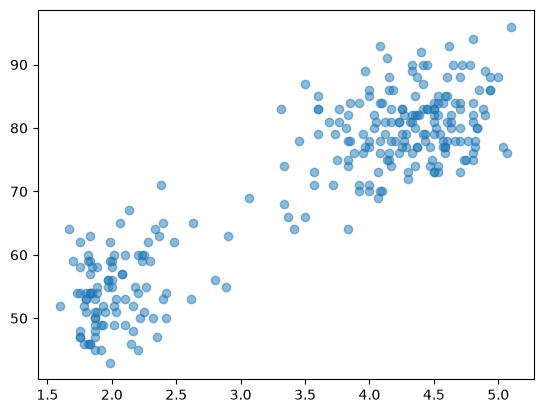

In [6]:
# Load the "Old Faithful" dataset from the Seaborn library

import seaborn
df = seaborn.load_dataset('geyser')
X_geyser = df[['duration', 'waiting']].values # (272, 2)

plt.scatter(X_geyser[:, 0], X_geyser[:, 1], alpha=0.5)

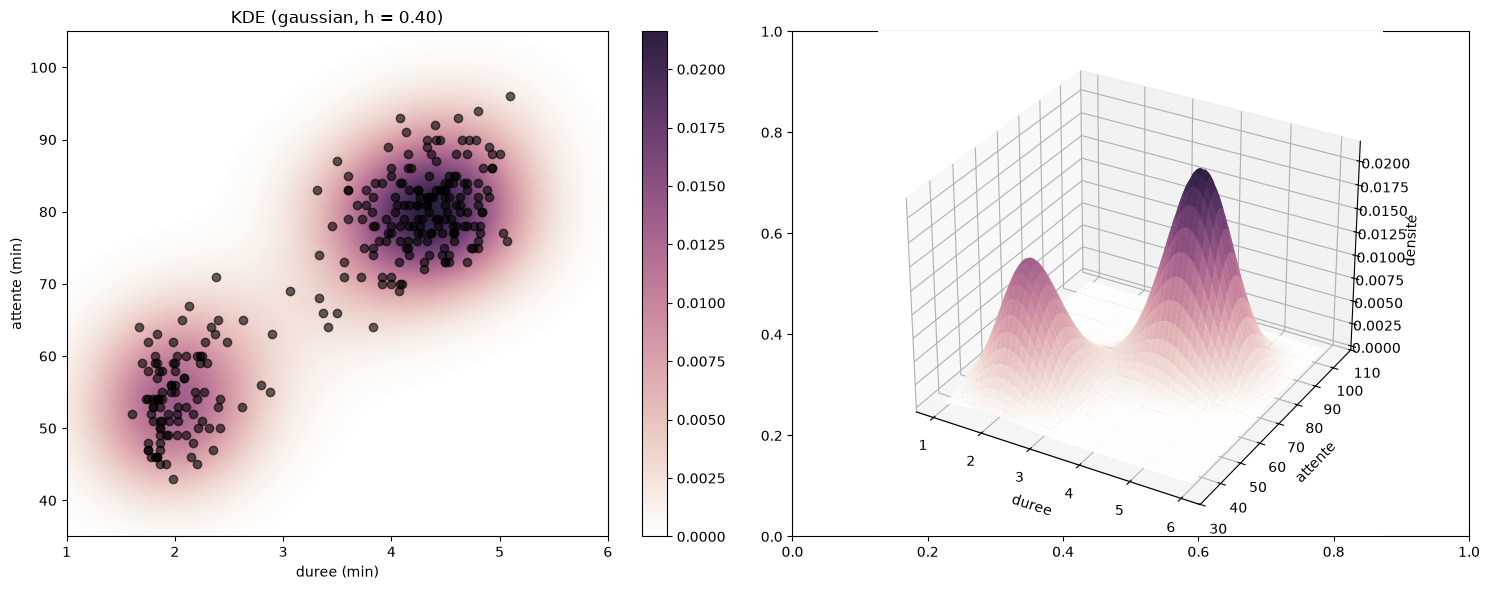

In [7]:
from sklearn.preprocessing import StandardScaler

h = 0.4
k = 'gaussian' # gaussian, tophat, epanechnikov, exponential, linear, cosine

# Use scikit-learn to estimate the density

# on standardise les données pour qu'une seule valeur de h soit valable pour les deux dimensions
# sinon, étant donné la différence d'échelle entre les deux dimensions, un même h donnerait un comportement différent entre les 2 dimensions 
scaler = StandardScaler()
X_geyser_norm = scaler.fit_transform(X_geyser)

cmap = sns.cubehelix_palette(start=6, light=1, as_cmap=True) # on reprend la palette de couleurs du TP1

xx = np.linspace(1, 6, 200) # de 1 à 6 min de durée
yy = np.linspace(35, 105, 200) # de 35 à 105 min d'attente
# on prépare la grille 2d pour l'affichage
XX, YY = np.meshgrid(xx, yy) # (200, 200)*2 quadrillage de l'espace
grid = np.column_stack([XX.flatten(), YY.flatten()]) # liste les points de la grille, (N*N, 2)
extent = [xx.min(), xx.max(), yy.min(), yy.max()] # extremums de la grille

# méthode des noyaux sur X normalisé, avec un unique h (d'où la nécessité de normaliser les données)
kde = KernelDensity(kernel=k, bandwidth=h).fit(X_geyser_norm)
# pour afficher les densités estimées, on utilise score_samples (comme précédemment) sur la grille pour calculer les log densités
log_densite = kde.score_samples(scaler.transform(grid)) # (N*N,) même taille que grid
# comme la kde a été faite sur les données normalisées, on doit diviser par le produit des écarts-types pour revenir à l'échelle d'origine
# ie, f_X(x) = f_X_norm(z) / (sigma_1 * sigma_2)
# par exemple si X est uniforme sur [0, 10], sa densité vaut 0.1, mais donc X_norm=X/10 a une densité de 1
f_hat = np.exp(log_densite).reshape(XX.shape) / np.prod(scaler.scale_)

# Represent the density

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

im = axes[0].imshow(f_hat, origin='lower', extent=extent, cmap=cmap, aspect='auto') # affichage de la densité
# (ici on utilise imshow, on aurait aussi pu utiliser contourf comme dans le TP1)
axes[0].scatter(X_geyser[:, 0], X_geyser[:, 1], color='black', alpha=0.6) # affichage des points
axes[0].set_xlabel('duree (min)')
axes[0].set_ylabel('attente (min)')
axes[0].set_title(f'KDE ({k}, h = {h:.2f})')
fig.colorbar(im, ax=axes[0])

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.plot_surface(XX, YY, f_hat, cmap=cmap) # affichage en 3D de la densité
ax2.set_xlabel('duree')
ax2.set_ylabel('attente')
ax2.set_zlabel('densité')
 
fig.tight_layout()
plt.show()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

La méthode des noyaux permet d'estimer la densité de probabilité qui a généré les points du dataset geyser. On retrouve bien une densité bimodale, qui a été retrouvée à partir des échantillons sans faire d'hypothèse paramétrique sur la nature de la densité (contrairement à la méthode de maximum de vraisemblance d'un mélange gaussien en TP1). On retrouve donc les deux distributions trouvées en TP1 : éruptions courtes suivies d'attentes courtes, et éruptions longues suivies d'attente longues.

On utilise un noyau gaussien avec $h=0.4$ car elle semble donner de bons résultats. De plus, la valeur $h=0.4$ trouvée expérimentalement correspond à la valeur donnée par la règle de Scott (détaillée [dans la doc de scipy pour gaussian_kde](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.gaussian_kde.html)) qui permet de sélectionner le nombre de bins d'un histogramme (`n**(-1./(d+4))` = 0.39). Un plus petit $h$ donne une densité irrégulière (haute variance), un grand $h$ augmente le biais et supprime la distinction des deux modes.

On souligne que la normalisation des données est primordiale car un unique $h$ doit être sélectionné pour les 2 dimensions

</div>

### Partie 4 : Estimation par noyaux en 64D ! Un modèle génératif

Une fois la fonction de densité estimée par noyaux, nous pouvons échantillonner de cette loi. Ceci nous permet donc de générer "de fausses données". C'est ce que nous allons mettre en oeuvre sur un exemple simple avec des images. Estimer la densité nous permettra donc de créer un générateur d'images.


**Q1.** Pour cette dernière question, nous utiliserons le dataset *Digits* qui contient environ 1800 imagettes en niveaux de gris de taille 8 par 8, qui peuvent donc être représentées comme des vecteurs de taille 64. Ces imagettes représentent des numéros scannés de codes postaux.

- Estimer par noyaux de la densité en utilisant `scikit-learn`. Le choix du noyau et de la longueur de fenêtre sont laissés libres.
- Afficher 10 images du dataset, puis 10 images échantillonnées à partir de la loi estimée. On utilisera la méthode `.sample`.
- Commenter.

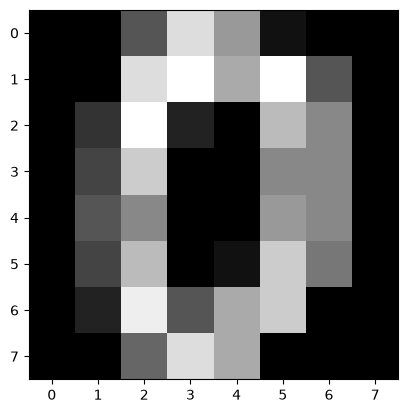

In [12]:
from sklearn.datasets import load_digits

X_digits = load_digits().data # (1797, 64)

plt.imshow(X_digits[0].reshape(8, 8), cmap='gray')
# 1 observation = 64 pixels / dimensions

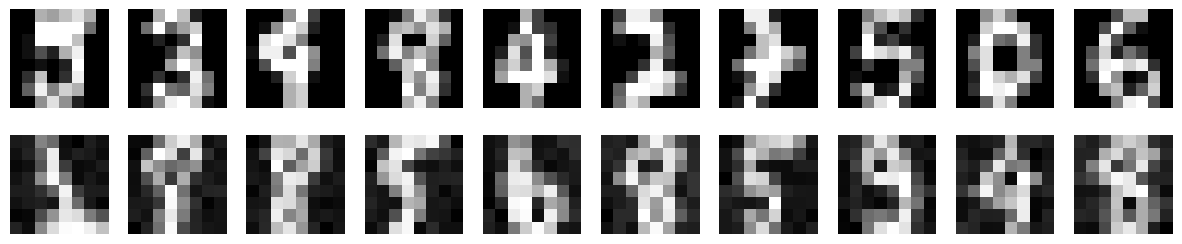

In [13]:
# tous les pixels ont la même échelle, on peut donc utiliser un unique h pour toutes les dimensions (pas besoin de normaliser)

from sklearn.model_selection import train_test_split
# on met de côté un jeu de test pour évaluer la vraisemblance de ces données test compte tenu du kde appris
X_train, X_test = train_test_split(X_digits, test_size=0.25)

# Use scikit-learn to estimate the density

k = 'gaussian' # gaussian, tophat
h = 0.9
kde = KernelDensity(kernel=k, bandwidth=h).fit(X_train)

# Generate 10 new samples

digits_generes = kde.sample(10)

# Plot 10 images from the dataset and 10 fake images obtained by sampling

fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(X_train[i].reshape(8, 8), cmap='gray')
    axes[0, i].axis('off')
    axes[1, i].imshow(digits_generes[i].reshape(8, 8), cmap='gray')
    axes[1, i].axis('off')

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On utilise le noyau gaussien, avec la règle de Scott pour fixer $h$ = `n**(-1./(d+4))` = 0.9. Les images générées semblent en effet proches de vrais chiffres, bien qu'un peu diffuses.

On teste aussi le noyau tophat, qui semble produire des images encore plus réalistes. Seulement, on ne peut pas savoir à ce moment là si les images générées sont de vraies "interpolations" d'images ou bien simplement des images recopiées. On utilise alors un set de test sur lequel on va évaluer la log-vraisemblance de notre KDE : 

</div>

In [19]:
H = [0.1, 0.2, 0.46, 0.9, 1.5, 1.7, 2.0, 2.5, 3.0]
ll_gaussian = []

for k in ['gaussian', 'tophat']:
    for h in H:
        kde = KernelDensity(kernel=k, bandwidth=h).fit(X_train)
        log_L = kde.score_samples(X_test) # (n_test,)
        print(f'{k:8s}  h = {h:<5}  log-vraisemblance moyenne = {log_L.mean():10.1f}')

        if k == 'gaussian':
            ll_gaussian.append(log_L.mean())

gaussian  h = 0.1    log-vraisemblance moyenne =   -18406.8
gaussian  h = 0.2    log-vraisemblance moyenne =    -2658.8
gaussian  h = 0.46   log-vraisemblance moyenne =     -425.0
gaussian  h = 0.9    log-vraisemblance moyenne =     -181.4
gaussian  h = 1.5    log-vraisemblance moyenne =     -144.8
gaussian  h = 1.7    log-vraisemblance moyenne =     -143.2
gaussian  h = 2.0    log-vraisemblance moyenne =     -143.4
gaussian  h = 2.5    log-vraisemblance moyenne =     -148.1
gaussian  h = 3.0    log-vraisemblance moyenne =     -152.8
tophat    h = 0.1    log-vraisemblance moyenne =       -inf
tophat    h = 0.2    log-vraisemblance moyenne =       -inf
tophat    h = 0.46   log-vraisemblance moyenne =       -inf
tophat    h = 0.9    log-vraisemblance moyenne =       -inf
tophat    h = 1.5    log-vraisemblance moyenne =       -inf
tophat    h = 1.7    log-vraisemblance moyenne =       -inf
tophat    h = 2.0    log-vraisemblance moyenne =       -inf
tophat    h = 2.5    log-vraisemblance m

(-500.0, 0.0)

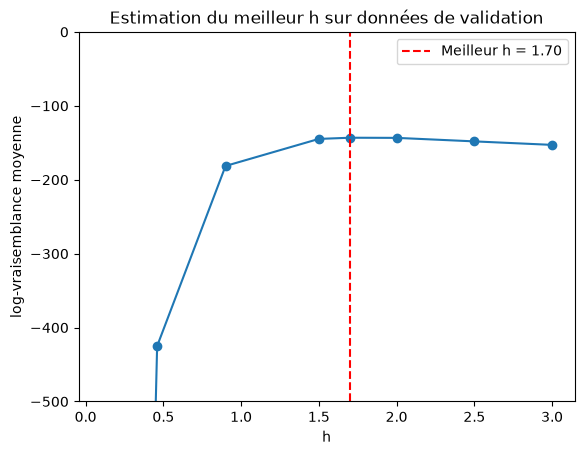

In [29]:
plt.plot(H, ll_gaussian, 'o-')
# vertical line to show the best h
best_h = H[np.argmax(ll_gaussian)]
plt.axvline(best_h, color='r', linestyle='--', label=f'Meilleur h = {best_h:.2f}')
plt.legend()

plt.title("Estimation du meilleur h sur données de validation")
plt.xlabel("h")
plt.ylabel("log-vraisemblance moyenne")

plt.ylim(-500, 0)

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On retrouve le résultat "fil rouge" de ce TP, qui est de dire que plus $h$ est petit, plus on est dans un cas de sur-apprentissage / haute variance. Au contraire, plus $h$ est grand, moins on dépend des données d'entraînement. Dans ce cas, choisir un $h$ autour de 2 semble donner le meilleur compromis.

On remarque que pour le noyau tophat, peu importe la valeur de $h$, on trouve une valeur de -infini pour la log-vraisemblance. Les exemples générés par tophat étaient donc des copies des observations.

Si l'on revient à la construction de l'estimateur par la méthode des noyaux (Q1, Partie 2), chaque observation apporte une masse à $\hat{f}_n$ autour de là où elle se trouve. Ainsi, générer un échantillon à partir de $\hat{f}_n$ revient à, dans l'espace des observations, choisir une observation du train set et se déplacer dans l'espace d'un petit bruit (de taille caractéristique $h$). L'endroit où on arrive est le sample généré.

Si une observation jamais vue X_test est en dehors de la "zone de bruit" de n'importe quelle observation du train set, alors la log-vraisemblance de X_test sera $-\inf$. Et comme la zone de bruit imposée par le noyau tophat est bornée, il suffit que X_test tombe un peu en dehors de cette zone pour avoir la log-vraisemblance égale à $-\inf$.

Or, à cause du fléau de la dimension, les observations sont en réalité très éloignées les unes des autres dans l'espace. Ainsi, chacune des données tests tombe souvent dans une région de l'espace où aucune observation du train set ne se trouve à proximité : la log-vraisemblance moyenne vaut donc $-\inf$. Ce problème du fléau de la dimension impacte tous les noyaux, et c'est amplifié par tophat qui impose une zone bornée (où la log-vraisemblance chute directement à $-\inf$, plutôt qu'une zone continue).

Cela montre donc le problème de la méthode des noyaux en haute dimension : plus le nombre de dimensions augmente, plus il faut de données pour s'assurer que les observations soient proches entre elles dans l'espace. On peut penser à des méthodes de réduction de dimension pour appliquer KDE sur des données de grande dimension.

Pour revenir sur la méthode décrite en Q4 (Partie 2), on estime qu'avec un noyau gaussien, le meilleur $h$ se situe autour de 1.7.

</div>